**SAPIANS** · SCC5819 · MÓDULO 06 — PDP · MOLNAR, CAP. 19

# A média dos perfis revela o modelo e esconde a diversidade

O SHAP repartia previsões locais; agora retomamos os perfis ICE para estudar a resposta média do preditor.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pdp/notebooks/pdp_walkthrough.ipynb)

---

**Objetivos.** Executar o método no modelo fixo do curso, conferir a fórmula e delimitar o que a medida permite concluir.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Forçar, prever, calcular a média

Para uma entrada $j$, $PD_j(z)=n^{-1}\sum_i f(z,x_{i,-j})$. Cada coluna da matriz ICE usa o mesmo valor da grade; sua média é o PDP. A faixa central resume a dispersão das previsões individuais e não um intervalo de confiança.

def pd_empirica(prever, fundo: pd.DataFrame, pontos: pd.DataFrame) -> np.ndarray:
    """PD_S(z) = média de f(z, X_-S) no mesmo fundo, sem interpolação.

    Uma linha de `pontos` define valores conjuntos de S. Combinações repetidas
    reutilizam a média, preservando a ordem e os pesos das linhas recebidas.
    A distribuição conjunta das colunas complementares permanece intacta.
    """
    if fundo.empty or pontos.empty or not len(pontos.columns):
        raise ValueError("Fundo e pontos precisam de linhas e colunas.")
    cache = {}
    resultado = []
    for valores in pontos.itertuples(index=False, name=None):
        if valores not in cache:
            alterada = substituir(fundo, dict(zip(pontos.columns, valores)))
            cache[valores] = float(np.asarray(prever(alterada), dtype=float).mean())
        resultado.append(cache[valores])
    return np.asarray(resultado)

Pontos da grade: 21
Quantis da grade (%): 2 98
Limites da grade de idade: 0,129281 95,485943
PDP na menor 

figura: figures_generated/pdp-idade.png


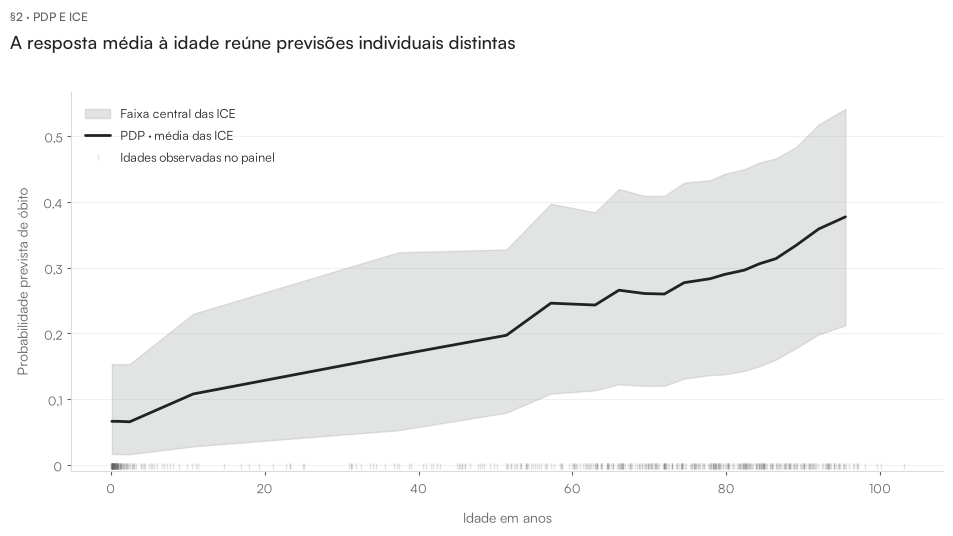

In [4]:
print(inspect.getsource(G.pd_empirica))
grade = np.unique(np.quantile(painel["idade_anos"], np.linspace(0.02, 0.98, 21)))
ice = G.ice_empirica(prever, xf, "idade_anos", grade)
pdp = G.pd_empirica(prever, xf, pd.DataFrame({"idade_anos": grade}))
assert np.allclose(pdp, ice.mean(axis=0), atol=1e-12)
print("Pontos da grade:", SP.pt_int(len(grade)))
print("Quantis da grade (%):", SP.pt_int(2), SP.pt_int(98))
print("Limites da grade de idade:", SP.pt(grade[0], 6), SP.pt(grade[-1], 6))
print("PDP na menor e maior idade:", SP.pct(pdp[0]), SP.pct(pdp[-1]))
print("Diferença entre pontas, p.p.:", SP.pt(100 * (pdp[-1] - pdp[0]), 3))
print(
    "Diferença máxima PDP e média ICE:",
    SP.pt_sig(np.max(np.abs(pdp - ice.mean(axis=0))), 4),
)
print("Quantis da faixa de previsões individuais:", SP.pt_int(10), SP.pt_int(90))
fig, ax = plt.subplots(figsize=SP.SLOT)
lo, hi = np.quantile(ice, [0.1, 0.9], axis=0)
ax.fill_between(
    grade, lo, hi, color=SP.CINZA_CLARO, alpha=0.3, label="Faixa central das ICE"
)
ax.plot(grade, pdp, color=SP.ESCURO, label="PDP · média das ICE")
ax.plot(
    painel["idade_anos"],
    np.full(len(painel), 0.015),
    "|",
    transform=ax.get_xaxis_transform(),
    color=SP.CINZA,
    alpha=0.18,
    markersize=5,
    label="Idades observadas no painel",
)
ax.set(xlabel="Idade em anos", ylabel="Probabilidade prevista de óbito")
ax.legend()
SP.titulo(
    fig,
    "A resposta média à idade reúne previsões individuais distintas",
    "§2 · PDP e ICE",
)
SP.salvar(fig, "pdp-idade")
plt.show()

**O que olhar.**

- Compare as pontas impressas sem chamar a diferença de efeito causal.
- A igualdade numérica com a média ICE confere o mecanismo; a faixa mostra dispersão entre fichas.

## §3 — Uma categoria por vez, sem inventar uma ordem

Saturação baixa é uma categoria do formulário. O PDP substitui a categoria em todas as fichas, preservando seus níveis nativos. A auditoria compara as cercas antes e depois e não remove silenciosamente linhas problemáticas.

      estado       PD fora da coorte novas fora da coorte
desconhecido 0,189000             16                   16
         nao 0,157061             16                   16
         sim 0,251229              0                    0
figura: figures_generated/pdp-saturacao-suporte.png


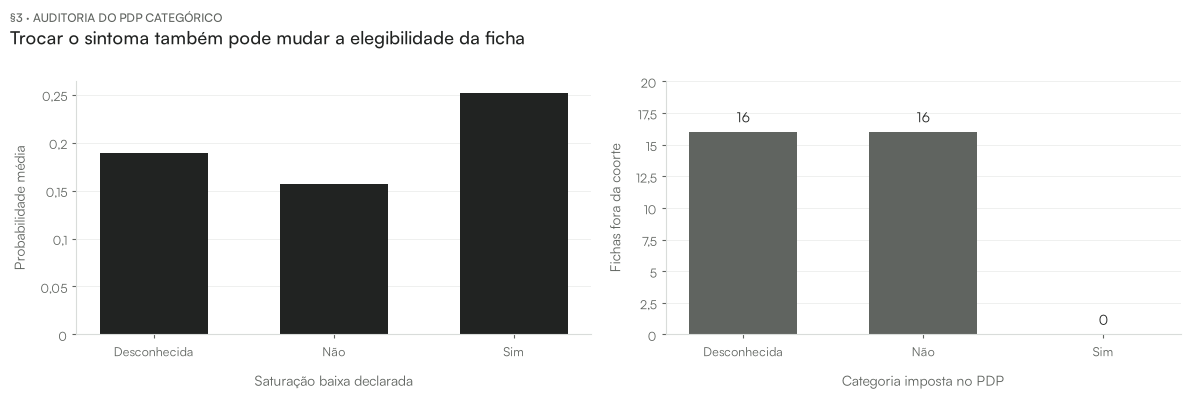

In [5]:
estados = list(xf["saturacao"].cat.categories)
valores = G.pd_empirica(prever, xf, pd.DataFrame({"saturacao": estados}))
audit = []
original_gate = M.gate_reasons(fundo)
for estado, valor in zip(estados, valores):
    rows = G.substituir(fundo, {"saturacao": estado})
    gates = M.gate_reasons(rows)
    audit.append(
        {
            "estado": estado,
            "PD": valor,
            "fora da coorte": int(gates["fora_coorte"].sum()),
            "novas fora da coorte": int(
                (gates["fora_coorte"] & ~original_gate["fora_coorte"]).sum()
            ),
        }
    )
audit = pd.DataFrame(audit)
print(SP.tabela(audit, casas=6))
fig, axes = plt.subplots(1, 2, figsize=SP.FAIXA)
rotulos = ["Desconhecida", "Não", "Sim"]
axes[0].bar(rotulos, valores, color=SP.ESCURO, width=0.6)
axes[0].set(ylabel="Probabilidade média", xlabel="Saturação baixa declarada")
axes[1].bar(rotulos, audit["fora da coorte"], color=SP.CINZA, width=0.6)
axes[1].set_ylim(0, max(audit["fora da coorte"]) * 1.25)
for i, valor in enumerate(audit["fora da coorte"]):
    axes[1].annotate(
        SP.pt_int(valor),
        (i, valor),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        color=SP.ESCURO,
        fontsize=10,
    )
axes[1].set(ylabel="Fichas fora da coorte", xlabel="Categoria imposta no PDP")
SP.titulo(
    fig,
    "Trocar o sintoma também pode mudar a elegibilidade da ficha",
    "§3 · Auditoria do PDP categórico",
)
SP.salvar(fig, "pdp-saturacao-suporte")
plt.show()

**O que olhar.**

- A tabela separa previsões e elegibilidade: Unknown/desconhecido é um estado, não uma negação.
- As contagens de novas violações dizem respeito ao fundo sorteado e à cerca declarada.

## §4 — O fundo também faz parte da resposta

A mesma grade é avaliada no fundo maior, no painel e no teste inteiro. A comparação mede sensibilidade de integração; não é uma nova avaliação de generalização.

Maior diferença fundo vs painel, p.p.: 0,2863
Maior diferença fundo vs teste inteiro, p.p.: 0,4474
figura: figures_generated/pdp-fundos.png


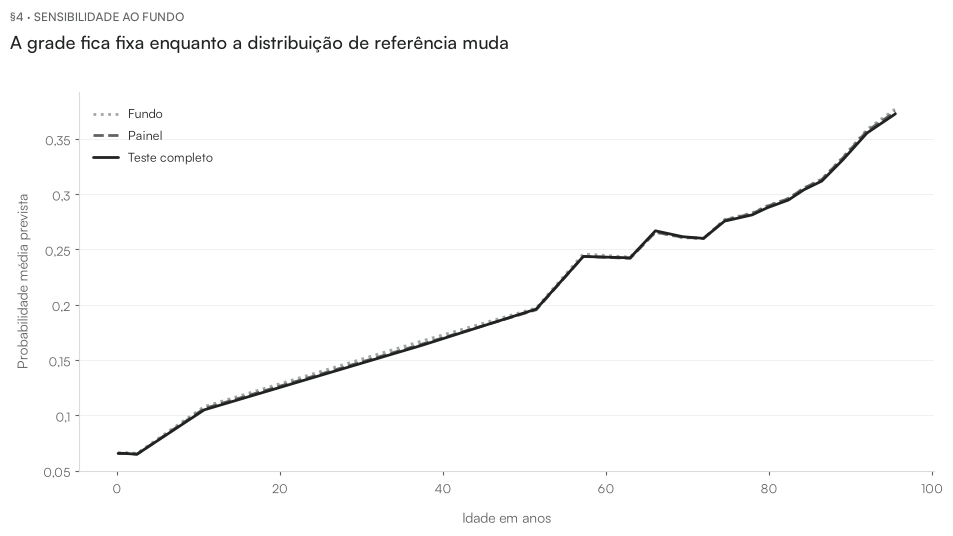

In [6]:
inteiro = M.design_matrix(teste)[0]
pd_painel = G.pd_empirica(prever, xp, pd.DataFrame({"idade_anos": grade}))
pd_teste = G.pd_empirica(prever, inteiro, pd.DataFrame({"idade_anos": grade}))
print(
    "Maior diferença fundo vs painel, p.p.:",
    SP.pt(100 * np.max(np.abs(pdp - pd_painel)), 4),
)
print(
    "Maior diferença fundo vs teste inteiro, p.p.:",
    SP.pt(100 * np.max(np.abs(pdp - pd_teste)), 4),
)
fig, ax = plt.subplots(figsize=SP.SLOT)
for values, label, color, estilo in [
    (pdp, "Fundo", SP.CINZA_CLARO, ":"),
    (pd_painel, "Painel", SP.CINZA, "--"),
    (pd_teste, "Teste completo", SP.ESCURO, "-"),
]:
    ax.plot(grade, values, label=label, color=color, linestyle=estilo)
ax.set(xlabel="Idade em anos", ylabel="Probabilidade média prevista")
ax.legend()
SP.titulo(
    fig,
    "A grade fica fixa enquanto a distribuição de referência muda",
    "§4 · Sensibilidade ao fundo",
)
SP.salvar(fig, "pdp-fundos")
plt.show()

**O que olhar.**

- A diferença máxima impressa quantifica a aproximação pela subamostra nesta grade.
- Curvas próximas sob fundos semelhantes não demonstram ausência de extrapolação.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/pdp.html) orienta o mecanismo e a leitura. PDP é uma média marginal de previsões. A comparação com ICE revela heterogeneidade; o controle das fichas alteradas torna visível a extrapolação. O caso SRAG acrescenta restrições do formulário, seleção hospitalar e deriva temporal. Nenhuma curva é uma estimativa do efeito de tratar ou modificar uma pessoa.

## §5 — Auditoria da base e da amostra de explicação

A referência é a amostra Gold commitada do projeto, não a extração bruta inteira do SIVEP-Gripe. Conferimos sua integridade e comparamos o painel com o teste temporal completo. As distribuições descritivas abaixo não demonstram representatividade populacional. O desfecho entra apenas nesta descrição posterior ao sorteio, nunca na construção das curvas.

O livro e o pacote foram inspecionados em revisões fixadas: [fonte do livro](https://github.com/christophM/interpretable-ml-book/tree/8f470c85e5ed4ebd69de74425cb9832f1bdc25eb) e [fonte de iml](https://github.com/giuseppec/iml/tree/4818c8f81dea2e76318857fbc3d50bc78cdd22f6). A avaliação distingue fórmula, configuração numérica, aplicação na base e alcance da interpretação. Não executamos o pacote R: as conferências de seu algoritmo são traduções explícitas para Python, identificadas nos internals.


In [7]:
from scipy.stats import ks_2samp

amostra_sha = hashlib.sha256(path.read_bytes()).hexdigest()
assert amostra_sha == "cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918"
assert gold["gold_id"].is_unique
assert not set(gold.loc[tr, "gold_id"]) & set(teste["gold_id"])
linhas = []
for nome, base in [("Teste temporal", teste), ("Painel", painel), ("Fundo", fundo)]:
    xx, _, yy = M.design_matrix(base)
    linhas.append(
        {
            "referência": nome,
            "fichas": len(base),
            "óbitos observados": int(yy.sum()),
            "fração óbito": yy.mean(),
            "previsão média": prever(xx).mean(),
            "idade p10": base["idade_anos"].quantile(0.1),
            "idade mediana": base["idade_anos"].median(),
            "idade p90": base["idade_anos"].quantile(0.9),
            "saturação sim": (base["saturacao"] == "sim").mean(),
            "saturação desconhecida": (base["saturacao"] == "desconhecido").mean(),
            "células ausentes em X": int(xx.isna().sum().sum()),
            "fora da coorte": int(M.gate_reasons(base)["fora_coorte"].sum()),
        }
    )
print(SP.tabela(pd.DataFrame(linhas), casas=6))
print("Identificadores únicos e treino/teste sem sobreposição:", True)
print(
    "Distância KS descritiva da idade, painel vs teste:",
    SP.pt(ks_2samp(painel["idade_anos"], teste["idade_anos"]).statistic, 6),
)
cat_p = painel["saturacao"].value_counts(normalize=True)
cat_t = teste["saturacao"].value_counts(normalize=True)
print(
    "Variação total da saturação, painel vs teste:",
    SP.pt(0.5 * (cat_p - cat_t).abs().sum(), 6),
)
print("Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb")
print("iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd22f6")
print("Execução nativa em R nesta auditoria:", False)

    referência fichas óbitos observados fração óbito previsão média idade p10 idade mediana idade p90 saturação sim saturação desconhecida células ausentes em X fora da coorte
Teste temporal 16.142             2.945     0,182443       0,215373  0,583436     68,555786 89,472961      0,616528               0,138397                     0              0
        Painel    512                94     0,183594       0,219387  0,760575     69,393570 90,069270      0,640625               0,134766                     0              0
         Fundo    256                51     0,199219       0,224372  0,947296     70,046539 90,754280      0,660156               0,140625                     0              0
Identificadores únicos e treino/teste sem sobreposição: True
Distância KS descritiva da idade, painel vs teste: 0,040275
Variação total da saturação, painel vs teste: 0,024097
Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb
iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd

## Fechamento — A medida só faz sentido com seu condicionamento

Identifique preditor, escala, fundo, grade e regra de ponderação antes de interpretar a figura. Uma reconstrução algébrica ou um controle sintético valida o cálculo sob suas hipóteses; não valida as combinações artificiais como pacientes plausíveis.

In [8]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 19](https://christophm.github.io/interpretable-ml-book/pdp.html). Referências completas e configuração no [README](../README.md).